<a href="https://colab.research.google.com/github/Diego230703/S7-Project-ConnectaTel/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ConnectaTel Latam – Análisis de Comportamiento y Segmentación de Clientes

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos
print(users.isna().mean()) # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


### 📝 Diagnóstico de Valores Nulos

#### **1. Dataset `users`:**
* **`city` (469 nulos / ~11.73%):**
  * *Diagnóstico:* Está en el rango del 5% al 30%.
  * *Acción recomendada:* Investigar para decidir si se imputa (por ejemplo, con una etiqueta como "No especificada") o se deja como nulo, ya que no amerita eliminar la columna.
* **`churn_date` (3,534 nulos / ~88.35%):**
  * *Diagnóstico:* Supera el 80% de valores faltantes.
  * *Acción recomendada:* **No eliminar.** Aunque el porcentaje es alto, su ausencia tiene un sentido lógico de negocio: indica que el usuario sigue activo y no se ha dado de baja.

---

#### **2. Dataset `usage`:**
* **`date` (50 nulos / ~0.13%):**
  * *Diagnóstico:* Porcentaje menor al 5%.
  * *Acción recomendada:* Caso simple de imputación o dejar como nulo al representar una proporción mínima que no afecta el análisis.
* **`duration` (22,076 nulos / ~55.19%):**
  * *Diagnóstico:* Alrededor del 55% de valores faltantes.
  * *Acción recomendada:* **Se investigará más** antes de tomar una decisión drástica; es probable que dependa del tipo de uso (`type`, como datos móviles que no requieren duración) y eliminarla afectaría el contexto.
* **`length` (17,896 nulos / ~44.74%):**
  * *Diagnóstico:* Cerca del 45% de valores faltantes.
  * *Acción recomendada:* **Se investigará más** para entender si está ligado a ciertas categorías específicas de transacciones o llamadas antes de evaluar cualquier eliminación.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- En la columna `user_id`, los valores son consecutivos y no muestran anomalías; es un identificador.
- La columna `age` presenta un *sentinel* de -999, indicando un "dato faltante" o "error".

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- En las columnas `id` y `user_id`, los valores son consecutivos y no muestran anomalías; son identificadores.
- Las columnas `duration` y `lenght`cuentan con valores plausibles, así que no cuentan con *sentinels* evidentes.

In [ ]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']]

for col in columnas_user:
    print(users[col].unique())

['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
['Basico' 'Premium']


- La columna `city` presenta dos *sentinels*, siendo ? y nan, indicando "datos faltantes" o "errores".
- La columna `plan`  se ve limpia, sin valores raros.

In [ ]:
# explorar columna categórica de usage
usage['type'].unique() # completa el código

array(['call', 'text'], dtype=object)

- La columna `type` se ve limpia, sin valores raros.


### 🔍 Diagnóstico de Valores Inválidos o Sentinels

#### **1. Columnas Numéricas (`users` y `usage`):**
* **`users['age']`:**
  * *Qué se observa:* Presenta un valor mínimo de `-999.000000`, el cual funciona como un *sentinel* (valor anómalo que representa un dato faltante o error de registro).
  * *Acción recomendada:* Reemplazar o tratar este valor `-999` como un valor nulo (`NaN`) para evitar sesgos en los cálculos estadísticos y análisis futuros.
* **`users['user_id']` y `usage['id'] / usage['user_id']`:**
  * *Qué se observa:* Valores secuenciales coherentes sin anomalías aparentes.
  * *Acción recomendada:* Mantener sin cambios al tratarse de identificadores válidos.
* **`usage['duration']` y `usage['length']`:**
  * *Qué se observa:* Sus valores estadísticos se encuentran en rangos plausibles (mínimos en 0 y máximos consistentes), por lo que no muestran *sentinels* evidentes a nivel numérico.
  * *Acción recomendada:* Conservar los datos actuales, teniendo en cuenta que los nulos ya fueron diagnosticados en el paso anterior.

---

#### **2. Columnas Categóricas:**
* **`users['city']`:**
  * *Qué se observa:* Contiene valores únicos como `['Medellín', '?', 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali']`. Presenta dos *sentinels* o valores inválidos: el signo de interrogación `?` y los valores nulos (`nan`).
  * *Acción recomendada:* Estandarizar el valor `?` tratándolo también como un valor faltante (`NaN`) para su posterior tratamiento junto con los nulos de la columna.
* **`users['plan']` y `usage['type']`:**
  * *Qué se observa:* Sus categorías (`'Basico'`, `'Premium'` para planes; `'call'`, `'text'` para tipos de uso) se encuentran limpias y sin valores extraños.
  * *Acción recomendada:* Mantener tal cual, ya que la distribución es correcta.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date` se observa la presencia de los años 2024, 2023 y 2022 con registros coherentes, pero destaca la presencia anómala del año 2026 con 40 registros, lo cual representa un año futuro imposible dado que los datos están registrados solo hasta 2024

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date` la gran mayoría de los registros corresponden al año 2024, aunque incluye valores nulos (`NaN`) generados por la conversión con `errors='coerce'` debido a datos de fecha corruptos o inválidos originales.

### 📅 Diagnóstico y Plan de Acción sobre Fechas

* **¿Aparecen años imposibles (años muy viejos o sin transcurrir al momento de guardar los datos)?**
  * **Sí.** En la columna `reg_date` del dataset `users` aparecen **40 registros con el año 2026**, lo cual es un año futuro imposible considerando que los datos registrados solo llegan hasta el año 2024. Asimismo, en la columna `date` del dataset `usage` se generaron valores nulos (`NaN`) derivados de cadenas de texto o formatos imposibles de convertir.

* **¿Qué harías con ellas?**
  * **Para el año 2026 en `reg_date`:** Dado que representan un error de captura o fechas futuras imposibles, se recomienda convertirlos a valores nulos (`NaN`) utilizando un filtro condicional de fecha máxima (2024) para evitar sesgos temporales en el análisis de altas de usuarios.
  * **Para los valores nulos (`NaN`) en `date` de `usage`:** Al haber sido convertidos por el parámetro `errors='coerce'`, se mantendrán como nulos y se evaluará su proporción (que previamente se identificó como mínima, de 50 registros o ~0.13%) para decidir si se excluyen de los cálculos de uso o se tratan según el requerimiento del análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
users['city'] = users['city'].fillna(pd.NA)

# Verificar cambios
users['city'].unique()

array(['Medellín', <NA>, 'CDMX', 'Bogotá', 'GDL', 'MTY', 'Cali'],
      dtype=object)

In [ ]:
# Marcar fechas futuras como NA para reg_date
mascara = users['reg_date'].dt.year == 2026
users.loc[mascara, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

### 📊 Diagnóstico de Valores Nulos en `duration` y `length` (MAR)

1. **Patrón encontrado:**
   Se identifica un comportamiento de tipo **MAR (Missing At Random)**. Los valores nulos en `duration` ocurren exclusivamente cuando el tipo de uso (`type`) es `"text"` (22,076 nulos), mientras que los nulos en `length` ocurren únicamente cuando `type` es `"call"` (17,896 nulos).

2. **Sentido conceptual:**
   Este patrón es completamente lógico desde el punto de vista del negocio: una llamada telefónica (`call`) se mide por su **duración** en el tiempo, por lo que carece de una longitud de caracteres de texto; a la inversa, un mensaje de texto (`text`) tiene una **longitud** de caracteres, pero no cuenta con una duración en segundos o minutos. Por lo tanto, la ausencia de datos no es un error, sino una característica estructural de la naturaleza de cada registro.

3. **Decisión tomada:**
   Se confirma que los valores son MAR y, siguiendo las instrucciones, **se dejarán como nulos (`NaN`)** sin realizar imputaciones artificiales ni eliminar las columnas, ya que su comportamiento depende directamente de la columna `type`.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text':'sum', 'is_call':'sum', 'duration':'sum'}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes', 'is_call':'cant_llamadas',
                                      'duration':'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

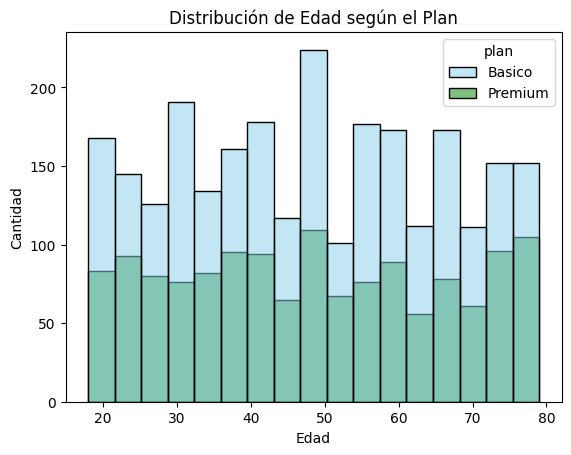

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.title('Distribución de Edad según el Plan')
plt.show()

💡Insights:
- **Distribución de edades:** La distribución general de las edades muestra un comportamiento bastante **uniforme y simétrico** a lo largo de los diferentes rangos de edad (desde los 20 hasta los 80 años), sin concentrarse fuertemente en un solo extremo ni mostrar un sesgo marcado hacia la izquierda o la derecha.
- **Proporción por tipo de plan:** Al analizar la proporción entre planes, los usuarios con el plan **Básico** (en celeste) y **Premium** (en verde) se encuentran distribuidos de manera equilibrada en la mayoría de los rangos de edad, manteniendo una proporción constante donde el plan Básico predomina ligeramente en número de usuarios en casi todos los intervalos.

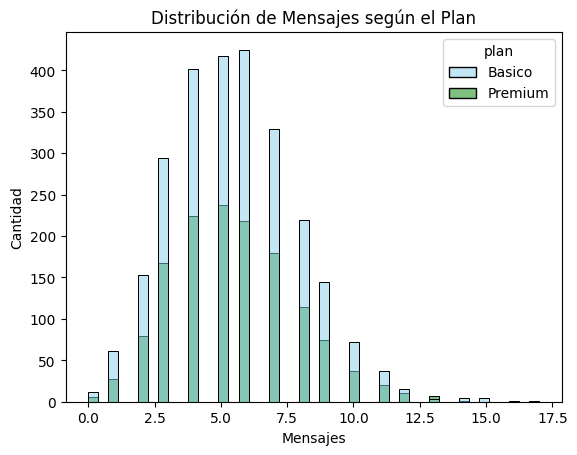

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.xlabel('Mensajes')
plt.ylabel('Cantidad')
plt.title('Distribución de Mensajes según el Plan')
plt.show()

💡Insights:
- **Distribución de mensajes:** La distribución de la cantidad de mensajes muestra un sesgo claro hacia la derecha, con una "cola" más larga que se extiende hacia los valores altos (superiores a 10 y hasta 17.5 mensajes), concentrando la mayor parte de los usuarios en un rango promedio de entre 4 y 7 mensajes.
- **Proporción por tipo de plan:** En cuanto a los planes, tanto los usuarios con plan **Básico** (celeste) como **Premium** (verde) siguen un patrón de comportamiento muy similar a lo largo de todo el rango, manteniendo una proporción constante y equilibrada sin diferencias drásticas en la cantidad de mensajes enviados según el tipo de plan.

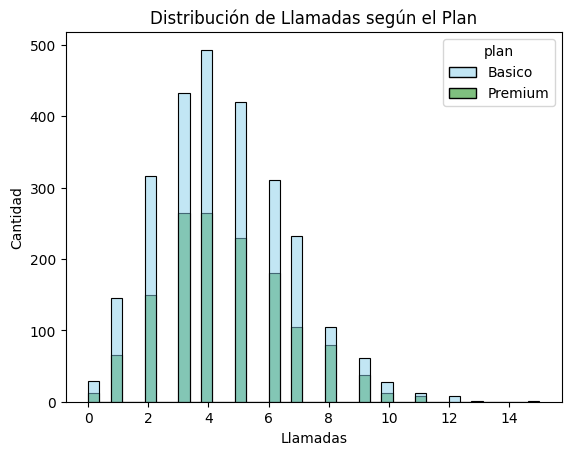

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.xlabel('Llamadas')
plt.ylabel('Cantidad')
plt.title('Distribución de Llamadas según el Plan')
plt.show()

💡Insights:
- **Distribución de llamadas:** La distribución de la cantidad de llamadas presenta un **sesgo hacia la derecha**, con una cola que se extiende gradualmente hacia los valores más altos (hasta cerca de 15 llamadas), concentrando el volumen principal de usuarios entre las 3 y 5 llamadas.
- **Proporción por tipo de plan:** En cuanto a los planes, los usuarios con plan **Básico** (celeste) y **Premium** (verde) muestran un comportamiento muy similar y proporcional a lo largo de todo el rango de llamadas, sin que se aprecie una diferencia drástica en la cantidad de llamadas realizadas entre ambos tipos de clientes.

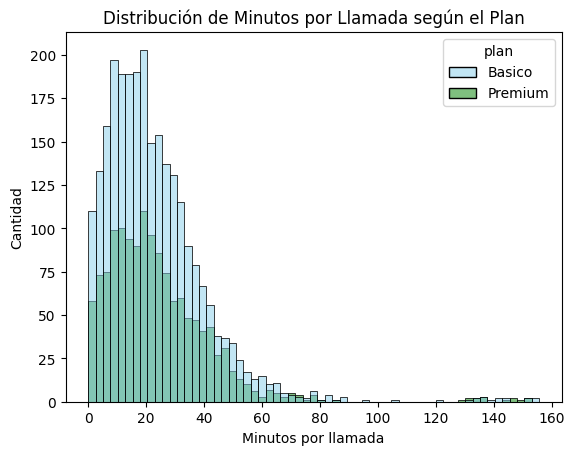

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.xlabel('Minutos por llamada')
plt.ylabel('Cantidad')
plt.title('Distribución de Minutos por Llamada según el Plan')
plt.show()

💡Insights:
- **Forma de la distribución y comparación de planes:** La distribución general presenta un **sesgo hacia la derecha**, concentrando la mayor parte de los valores de minutos por llamada entre los 0 y 60 minutos. Al igual que en las variables anteriores, los usuarios con plan **Básico** (celeste) y **Premium** (verde) muestran un comportamiento bastante equilibrado y proporcional a lo largo del rango principal.
- **Detección de valores atípicos (Outliers):** Se observa claramente un grupo aislado de barritas sueltas ubicadas en un rango superior, **entre los 130 y 160 minutos**, muy alejadas del bloque principal de datos. Esto anticipa la presencia de **outliers** o valores extremos que serán analizados y tratados en el siguiente apartado (Paso 5.2) mediante diagramas de caja y el método IQR.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

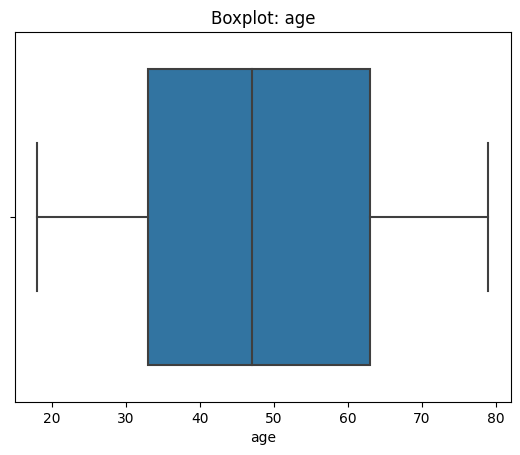

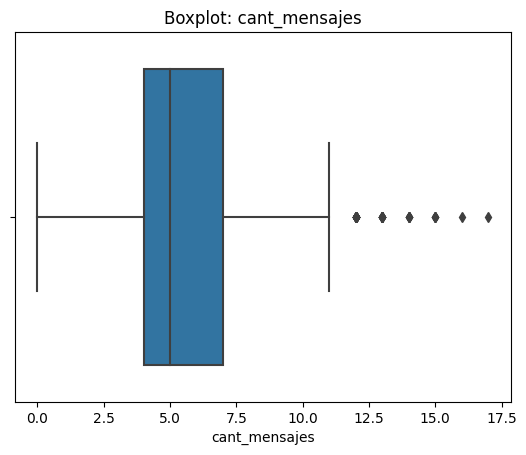

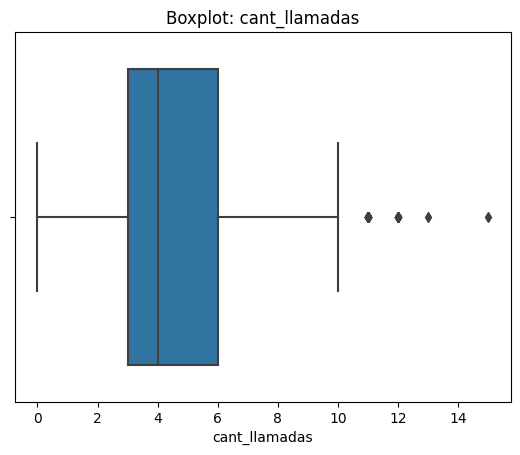

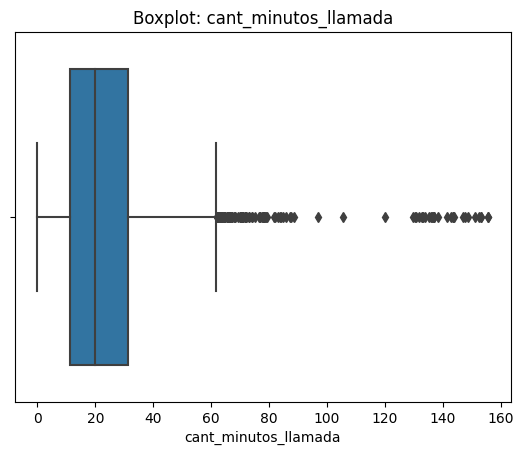

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights:
- **`age`:** No presenta outliers; la distribución de las edades se encuentra completamente contenida dentro de los bigotes del diagrama (aproximadamente entre los 18 y 80 años).
- **`cant_mensajes`:** Sí presenta outliers; se observa una serie de puntos individuales (valores atípicos) ubicados por encima del bigote superior, superando los 11.5 mensajes.
- **`cant_llamadas`:** Sí presenta outliers; se identifican algunos puntos aislados fuera del límite superior, rebasando las 10 llamadas.
- **`cant_minutos_llamada`:** Sí presenta outliers de forma clara y notable; cuenta con una gran cantidad de puntos dispersos más allá de los 60 minutos, extendiéndose hasta cerca de los 160 minutos, lo que coincide con los valores observados previamente en el histograma.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    IQR = q3 - q1
    limite_inferior = q1 - 1.5 * IQR
    limite_superior = q3 + 1.5 * IQR
    print(f'{col},', 'Límite inferior:', limite_inferior, 'Límite superior:',limite_superior)

cant_mensajes, Límite inferior: -0.5 Límite superior: 11.5
cant_llamadas, Límite inferior: -1.5 Límite superior: 10.5
cant_minutos_llamada, Límite inferior: -19.322500000000005 Límite superior: 61.8575


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- **`cant_mensajes`:** **Mantener los outliers.** Aunque superan estadísticamente el límite superior (11.5) llegando hasta 17, representan un comportamiento de usuario real y legítimo (*power users*). Si fueran errores de captura por fallos del sistema o registros duplicados, se investigaría el origen técnico para eliminarlos o corregirlos, pero en este caso reflejan actividad válida.
- **`cant_llamadas`:** **Mantener los outliers.** Los valores que rebasan el límite superior (10.5) hasta alcanzar las 15 llamadas corresponden a clientes con alta actividad. De tratarse de anomalías por errores de inserción en la base de datos o duplicidades, se procedería a filtrarlos; sin embargo, al ser métricas de uso reales, se decide conservarlas para no perder información valiosa.
- **`cant_minutos_llamada`:** **Mantener los outliers.** A pesar de superar el límite superior (61.86) y alcanzar los 155.69 minutos, estos datos reflejan llamadas prolongadas genuinas. Si se tratara de fallas técnicas o bugs de registro que duplicaran el tiempo en llamadas, se depurarían, pero aquí validan el comportamiento de usuarios altamente activos.

**¿Por qué no se calcularon los límites para `age`?**
  No se incluyó la columna `age` en el cálculo de límites con el método IQR porque en el análisis gráfico previo de los diagramas de caja (*boxplots*) se comprobó visualmente que la edad no presenta valores atípicos (*outliers*). Su distribución se encuentra completamente dentro de los rangos normales (delimitados por los bigotes del gráfico, aproximadamente entre los 18 y 80 años), por lo que no requiere una limpieza o tratamiento de valores extremos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
resultados = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, resultados, default='Alto uso')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones = [(user_profile['age'] <30), (user_profile['age'] < 60)]
resultados = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(condiciones, resultados, default='Adulto Mayor')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

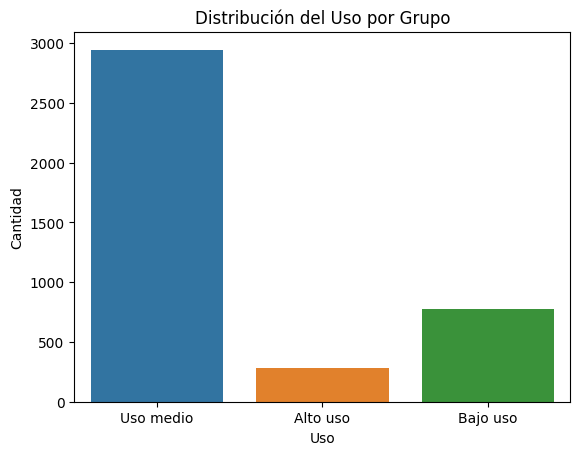

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.xlabel('Uso')
plt.ylabel('Cantidad')
plt.title('Distribución del Uso por Grupo')
plt.show()

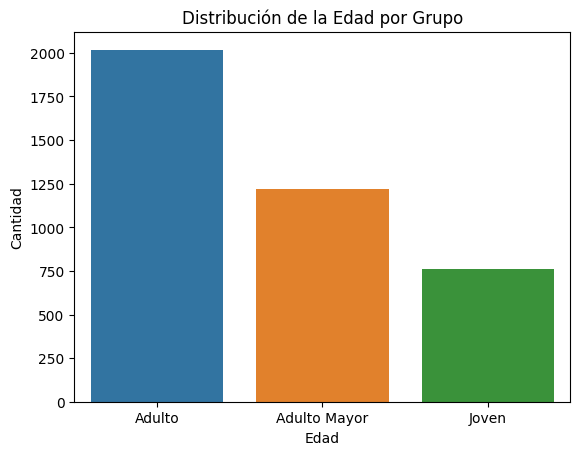

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.title('Distribución de la Edad por Grupo')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

## Análisis Ejecutivo de ConnectaTel: Clientes y Consumo (Latam)

### 1. Resumen Ejecutivo y Visión General del Negocio
ConnectaTel opera en el mercado de telecomunicaciones de Latinoamérica mediante dos esquemas tarifarios: el **Plan Básico** y el **Plan Premium**. El análisis histórico de la base de usuarios (4,000 registros y 40,000 interacciones) revela una alta concentración comercial en el plan de menor costo, acompañada de patrones estables en la adopción de servicios.

- **Distribución de planes:** El **Plan Básico** concentra el **64.88%** de los clientes, mientras que el **Plan Premium** representa el **35.12%**.
- **Evolución temporal:** Las altas de usuarios se han mantenido con volúmenes anuales estables (aprox. 1,300 registros anuales entre 2022 y 2024), con una tasa de cancelación (*churn*) histórica del **11.65%**.

### 2. Perfil Estadístico y Comportamiento de Uso
El consumo de voz y mensajería muestra distribuciones con sesgo positivo (*right-skewed*), donde la mayoría de los usuarios mantiene un consumo moderado y una minoría concentra los volúmenes más altos.

| Métrica (Promedio por Usuario) | Media | Mediana (P50) | P75 | Máximo |
| :--- | :---: | :---: | :---: | :---: |
| **Edad del cliente** | 48.12 años | 47.00 años | 63.00 años | 79.00 años |
| **Mensajes enviados** | 5.52 | 5.00 | 7.00 | 17.00 |
| **Llamadas realizadas** | 4.48 | 4.00 | 6.00 | 15.00 |
| **Minutos de llamada** | 23.32 min | 19.78 min | 31.42 min | 155.69 min |

> 📌 **Hallazgo Clave:** No se aprecian diferencias drásticas o barreras de uso exclusivas entre los usuarios Básicos y Premium en los volúmenes cotidianos de llamadas y mensajes. Esto sugiere que gran parte de los suscriptores Premium infrautilizan los beneficios de su tarifa.

### 3. Detección de Anomalías y Calidad de los Datos
Previo al modelado analítico, se aplicaron los siguientes protocolos de limpieza (*data cleaning*):
- **Valores atípicos (*sentinels*):** Corrección de edades anómalas (`-999`) sustituyéndolas por la mediana poblacional (47 años). Estandarización de ciudades con valores no especificados (`?`) a nulos (`NaN`).
- **Validación temporal:** Filtrado de 40 registros con marcas de tiempo erróneas en el año 2026, limitando el alcance temporal al año 2024.
- **Estructura MAR (*Missing At Random*):** Los valores nulos en `duration` y `length` responden a la naturaleza de la transacción (los mensajes no tienen duración en minutos y las llamadas no tienen longitud de caracteres), por lo que se conservaron estructuralmente.

### 4. Sugerencias y Recomendaciones Estratégicas
1. **Campañas comerciales segmentadas:** Dado que la segmentación muestra una dominancia absoluta del grupo **"Adulto"** en combinación con un **"Uso medio"** de los servicios, se debe evitar lanzar campañas masivas genéricas. En su lugar, conviene diseñar ofertas personalizadas de retención y paquetes de datos dirigidos específicamente a este clúster maduro de consumo moderado para incentivar el incremento de su uso (*upselling*).
2. **Estrategia de upselling y optimización:** Diseñar campañas para educar a los usuarios Premium sobre los beneficios de su plan o estructurar un **nivel intermedio (*tiering*)** que prevenga el *downgrade* o la cancelación.
3. **Mitigación de Churn:** Identificar a los usuarios en los percentiles más altos de minutos de llamada (>114 minutos) y ofrecerles bonificaciones por fidelidad para retenerlos frente a la competencia.
4. **Gobierno de datos:** Implementar validaciones estrictas en las interfaces de captura (impidiendo registros futuros como 2026 o códigos de error como `-999`) para agilizar auditorías futuras.

Link a repositorio público del proyecto: `https://github.com/Diego230703/S7-Project-ConnectaTel.git`